# Replace the contamination guess with a false-alarm rate

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OliverHennhoefer/nonconform/blob/main/examples/false_alarm_threshold.ipynb)

Most detectors turn scores into labels with `contamination`: a guess of the
share of anomalies in the data. If the guess is off, so is the number of normal
points you flag. nonconform asks a question you can answer instead: what share
of normal points can you afford to flag? `fpr_bounds()` returns a score
threshold that keeps that rate below your target, with a stated confidence.

The data is the Cardio dataset from `oddball`: 827 normal recordings for
reference and a test set of 275, of which 27 are pathological.

In [1]:
# On Colab or a fresh environment, install what this notebook needs.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("oddball") is None:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "nonconform[data]",
            "matplotlib",
        ],
        check=True,
    )

In [2]:
import numpy as np
from oddball import Dataset, load
from sklearn.ensemble import IsolationForest

from nonconform import ConformalDetector, Split

x_reference, x_test, y_test = load(Dataset.CARDIO, setup=True, seed=42)
normal, anomaly = y_test == 0, y_test == 1


def report(name, flagged):
    """Print how many points a rule flags and how many of them are normal."""
    print(
        f"{name:<28} flagged {int(flagged.sum()):>3}, "
        f"normal points flagged {flagged[normal].mean():5.1%}, "
        f"anomalies found {flagged[anomaly].mean():4.0%}"
    )

## The usual way: guess the contamination

In [3]:
baseline = IsolationForest(contamination=0.1, random_state=42).fit(x_reference)
report("contamination=0.1", baseline.predict(x_test) == -1)

contamination=0.1            flagged  55, normal points flagged 12.5%, anomalies found  89%


## The nonconform way: state the false-alarm rate

Hold out half of the reference data for calibration, then ask for the threshold
that flags at most 10% of normal points. `confidence=0.9` means the bound holds
in at least 90% of calibration draws.

In [4]:
detector = ConformalDetector(
    detector=IsolationForest(random_state=42),
    strategy=Split(n_calib=0.5),
    score_polarity="auto",
    seed=42,
).fit(x_reference)

certificate = detector.fpr_bounds(confidence=0.9)
scores = detector.score_samples(x_test)
threshold = certificate.threshold_for(0.1)
report("fpr_bounds, target 10%", certificate.select(scores, target_fpr=0.1))
report("select(alpha=0.1)", detector.select(x_test, alpha=0.1))
print(f"Certified threshold: {threshold:.4f}")

select() made no discoveries. With 414 calibration scores, classical conformal p-values cannot fall below 1/415 = 0.00241, but a single BH discovery among m = 275 tests needs p <= alpha/m = 0.000364. Any discovery requires at least 7 test points that jointly attain that minimum. Use at least 2749 calibration scores, or smaller test batches, so that a single anomaly can be discovered.


fpr_bounds, target 10%       flagged  35, normal points flagged  6.0%, anomalies found  74%
select(alpha=0.1)            flagged   0, normal points flagged  0.0%, anomalies found   0%
Certified threshold: -0.0777


`select()` returns nothing here: the detector does not separate these anomalies
well enough to promise a short list with at most 10% false entries. The
threshold still works, because it makes a different promise, about normal points
only.

## How the threshold is chosen

The certificate gives an upper bound on the false-alarm rate at every possible
threshold. The chosen threshold is the lowest one whose bound is below the
target. The bound is looser than the observed rate on the calibration scores,
and the gap shrinks as the calibration set grows. A target has a finite
threshold only if

```text
n_calib >= ln(1 / (1 - confidence)) / (2 * target_fpr**2)
```

For a 10% target at 90% confidence that is 116 calibration scores, and this
notebook has 414. A 5% target at 95% confidence needs about 600.

In [5]:
import matplotlib.pyplot as plt

NORMAL, ANOMALY, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "font.size": 10,
    }
)

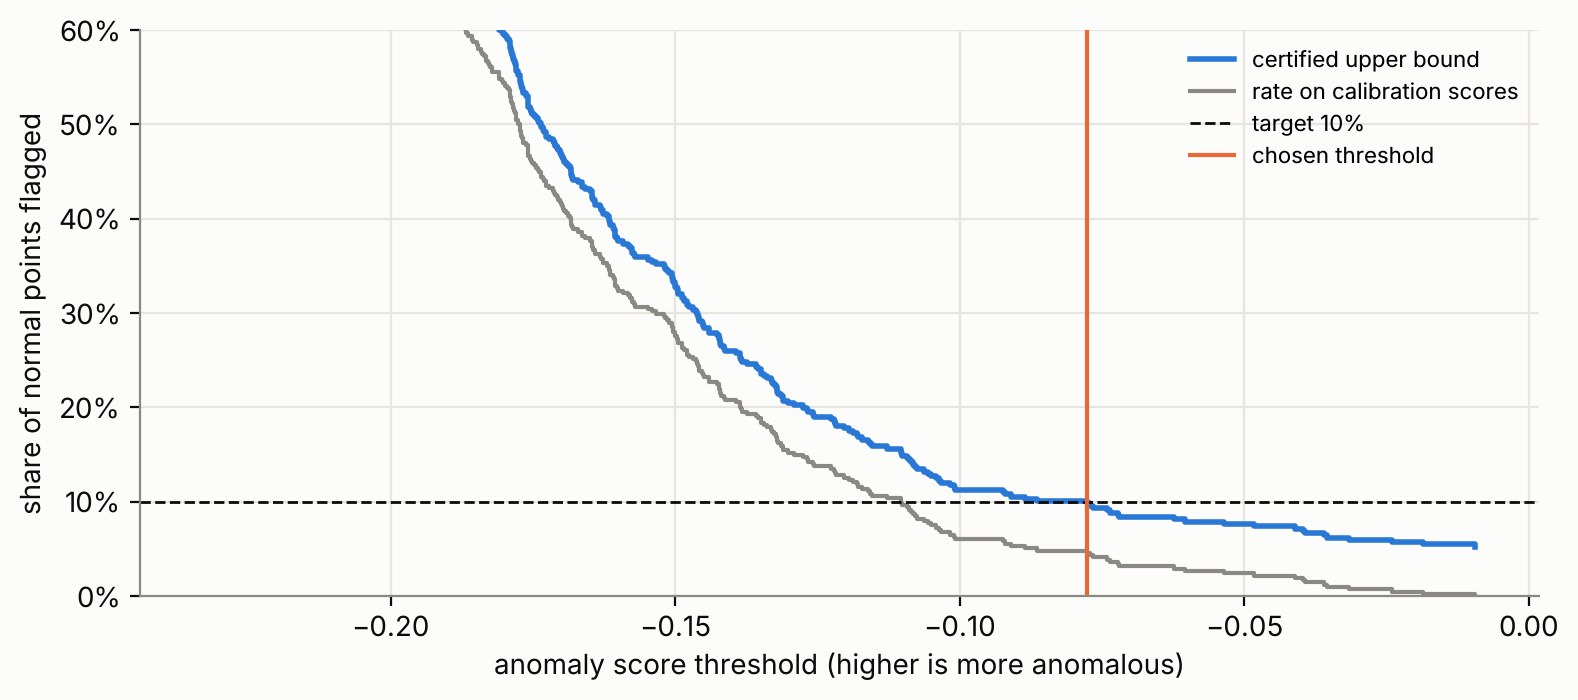

In [6]:
table = certificate.to_frame()
finite = np.isfinite(table["threshold"])
table = table[finite]

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.step(
    table["threshold"],
    table["fpr_upper_bound"],
    where="post",
    color=NORMAL,
    lw=2,
    label="certified upper bound",
)
ax.step(
    table["threshold"],
    table["empirical_fpr"],
    where="post",
    color=MUTED,
    lw=1.5,
    label="rate on calibration scores",
)
ax.axhline(0.1, color=INK, lw=1, ls="--", label="target 10%")
ax.axvline(threshold, color=ANOMALY, lw=1.5, label="chosen threshold")
ax.set(
    xlabel="anomaly score threshold (higher is more anomalous)",
    ylabel="share of normal points flagged",
    ylim=(0, 0.6),
)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

## What to take away

- Use `fpr_bounds()` where you would otherwise set `contamination`. The target
  is about normal points, so it does not depend on how many anomalies arrive.
- It does not limit the share of false flags in a list. For that, use
  `select()` and a large enough calibration set.
- The bound assumes the calibration data are clean normal points drawn
  independently from the same distribution as future normal points. See
  *Assumptions and guarantees* in the docs.